# Product Review Sentiment Analysis (Flipkart) — ML baseline + LLM

**Sections:** 1 Setup · 2 Data · 3 EDA · 4 Model comparison · 5 Final model · 6 Product analysis · 7 Word clouds · 8 LLM analysis · 9 LLM vs SVM · 10 Try your own review

## 1. Setup

In [2]:
import os, sys, getpass, yaml
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

sys.path.insert(0, os.getcwd())          # so `from src import ...` works
from src import classifier, eda
from src.preprocess import load_dataset
from src.prompts import load_prompts
from src.llm_client import LLMClient, find_api_key, key_env_name
from src.aspects import analyze_review
from src.summarize import summarize_product
from src.compare import run_comparison

cfg = yaml.safe_load(open("config.yaml"))
pd.set_option("display.max_colwidth", 80)
print("Config loaded. LLM provider:", cfg["llm"]["provider"], "| model:", cfg["llm"]["model"])

Config loaded. LLM provider: gemini | model: gemini-3.1-flash-lite


In [3]:
# API key for the LLM sections (provider is set in config.yaml -> llm.provider; default: free Gemini).
# Reads the key from .env or the environment; otherwise asks once.
# Press Enter to skip -- everything except sections 8-10 still runs without a key.
provider = cfg["llm"]["provider"]
KEY_NAME = key_env_name(provider)
load_dotenv()
if not find_api_key(provider):
    try:
        key = getpass.getpass(f"Paste your {KEY_NAME} (or press Enter to skip LLM sections): ")
        if key.strip():
            os.environ[KEY_NAME] = key.strip()
    except Exception:
        pass
HAS_KEY = bool(find_api_key(provider))
print(f"Provider: {provider} | key found: {HAS_KEY}")

Provider: gemini | key found: True


## 2. Load and clean the data
Drops missing values, converts stars to sentiment (4-5 Positive, 3 Neutral, 1-2 Negative) and builds `clean_review`.
**Identical review texts are collapsed to one row** (the same "Nice. Good product" appears under many products), so no review can sit in both the training and the test set.

In [4]:
path = cfg["data"]["full_path"] if os.path.exists(cfg["data"]["full_path"]) else cfg["data"]["sample_path"]
print("Using:", path)
df = load_dataset(path)
print(df.shape)
df[["Review", "Summary", "Rate", "Sentiment", "clean_review"]].head()

Using: data/flipkart_product.csv
(103568, 8)


,Review,Summary,Rate,Sentiment,clean_review
0,Super!,Great cooler.. excellent air flow and for this price. It's so amazing and un...,5.0,Positive,super great cooler excellent air flow and for this price it s so amazing and...
1,Awesome,Best budget 2 fit cooler. Nice cooling,5.0,Positive,awesome best budget fit cooler nice cooling
2,Fair,The quality is good but the power of air is decent,3.0,Neutral,fair the quality is good but the power of air is decent
3,Useless product,Very bad product it's a only a fan,1.0,Negative,useless product very bad product it s a only a fan
4,Fair,Ok ok product,3.0,Neutral,fair ok ok product


In [5]:
df["Sentiment"].value_counts()

Sentiment
Positive    75181
Negative    19314
Neutral      9073
Name: count, dtype: int64

## 3. Exploratory Data Analysis

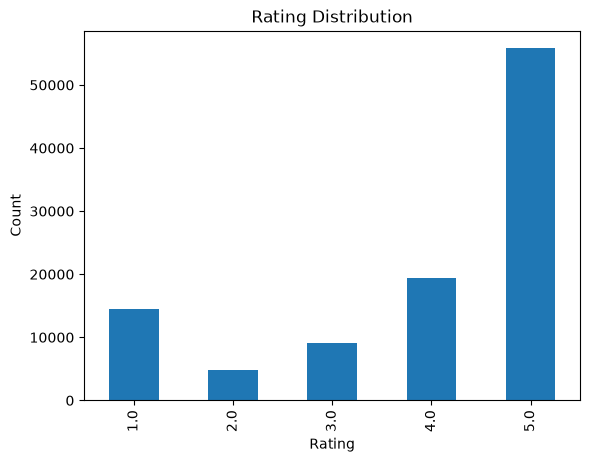

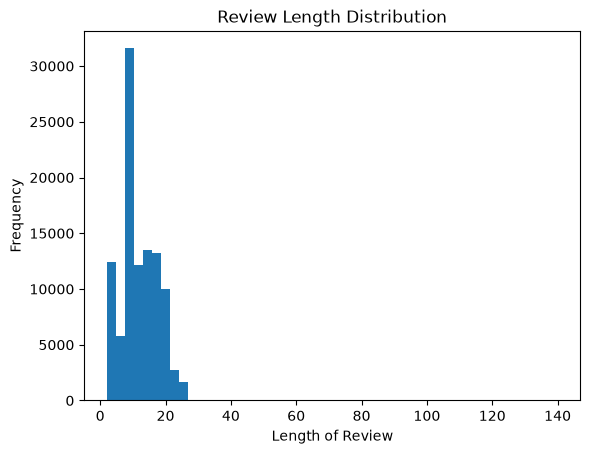

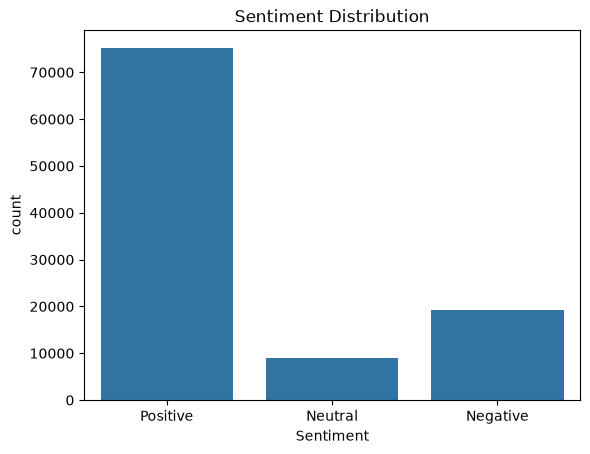

In [6]:
eda.plot_rating_distribution(df)
eda.plot_review_length(df)
eda.plot_sentiment_distribution(df)

**Observations:** the data is skewed towards 4-5 star reviews (~73% Positive, only ~9% Neutral), so the classes are imbalanced —
this is why the models use `class_weight="balanced"` and why we report macro-F1 (and per-class F1) next to accuracy.
The `Review` column is a short headline (typically under 30 characters); the longer text is in `Summary`, so both are combined for modelling.

## 4. Compare four classic models
Same TF-IDF features (unigrams + bigrams), same stratified 80/20 split, vectorizer fitted on the training set only.
Accuracy favours the big Positive class, so **Macro-F1** (all three classes weighted equally) is shown too.
⏱ 

In [7]:
results = eda.compare_models(df, cfg)
results

,Model,Accuracy,Macro-F1
0,SVM (LinearSVC),97.25,94.10
1,Logistic Regression,96.40,92.77
2,Random Forest,96.37,91.51
3,Naive Bayes,94.43,86.23


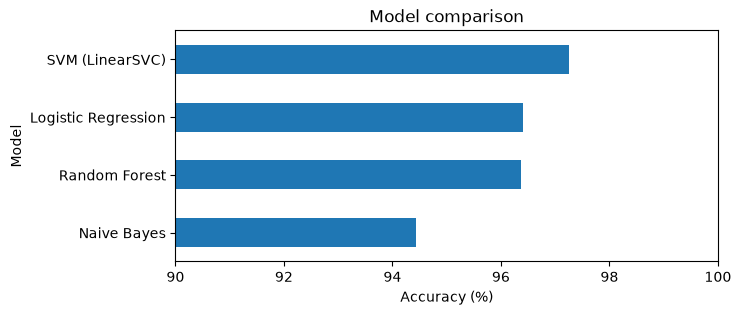

In [8]:
ax = results.plot(kind="barh", x="Model", y="Accuracy", legend=False, xlim=(90, 100), figsize=(7, 3))
ax.invert_yaxis(); ax.set_xlabel("Accuracy (%)"); ax.set_title("Model comparison")
plt.show()

## 5. Final model: TF-IDF + LinearSVC (SVM)
Trains on the training split, saves to `models/`, and prints precision / recall / F1 on the held-out test set.

In [9]:
print(classifier.train(df, cfg))

Train size: 82854  Test size: 20714
Accuracy: 0.9725

              precision    recall  f1-score   support

    Negative       0.96      0.97      0.97      3863
     Neutral       0.87      0.86      0.87      1815
    Positive       0.99      0.99      0.99     15036

    accuracy                           0.97     20714
   macro avg       0.94      0.94      0.94     20714
weighted avg       0.97      0.97      0.97     20714



In [10]:
svm = classifier.load_model(cfg["model_path"])
tests = ["This product quality is amazing",
         "The product was not as expected",
         "waste of money, stopped working in a week",
         "it is okay, does the job"]
for t in tests:
    print(f"{classifier.predict(svm, t):<9} <- {t}")

Positive  <- This product quality is amazing
Negative  <- The product was not as expected
Negative  <- waste of money, stopped working in a week
Neutral   <- it is okay, does the job


## 6. Product analysis
Products are ranked by the **percentage** of positive (or negative) reviews, using only products with at least 200 reviews.
(Ranking by raw counts would just list the most-reviewed products in both lists.)

In [11]:
best, worst = eda.product_analysis(df, min_reviews=200, top=10)
print("Most positively reviewed products"); display(best)
print("Most negatively reviewed products"); display(worst)

Most positively reviewed products


,reviews,positive_pct,negative_pct
ProductName,,,
"APPLE 2020 Macbook Air M1 - (8 GB/256 GB SSD/Mac OS Big Sur) MGN93HN/A (13.3 inch, Silver, 1.29 kg)",643,95.6,2.6
"HAIR & CARE Triple Blend Damage Repair Non-Sticky Hair Oil with Aloe Vera, For Dry, Rough, & Frizzy Hair, Hair Oil (400 ml)",895,93.5,2.9
APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with Wi-Fi Only (Space Grey),763,92.5,4.3
Hindware Nevio Plus 60 Auto Clean Wall Mounted Chimney (Black 1400 CMH),226,91.2,4.0
"IFB 23 L Convection Microwave Oven (23SC3, Silver)",311,90.7,4.8
"MSI Core i5 11th Gen - (8 GB/512 GB SSD/Windows 10 Home/4 GB Graphics/NVIDIA GeForce RTX 3050/144 Hz) GF63 Thin 11UC-867IN Gaming Laptop (15.6 Inch, Black, 1.86 Kg)",267,90.6,6.4
LIVPURE LIV-PEP-PRO-PLUS+ 7 L RO + UV + UF Water Purifier with Taste Enhancer (White),386,90.2,4.4
Dettol Effective Protection Antiseptic Liquid (1000 ml),324,88.9,5.2
"BAJAJ 17 L Solo Microwave Oven (1701MT, White)",408,88.5,5.9


Most negatively reviewed products


,reviews,positive_pct,negative_pct
ProductName,,,
Men Black Sandal,515,39.0,51.1
"S . K Store Carbon Steel Collapsible Wardrobe (Finish Color - Black, DIY(Do-It-Yourself))",244,39.8,47.1
"Simple Trending PP Collapsible Wardrobe (Finish Color - Navyblue, DIY(Do-It-Yourself))",233,36.5,44.6
Men Graphic Print Round Neck Black T-Shirt,513,44.4,42.5
"Men 9325 Latest Collection Stylish Sports Sneakers Running Shoes Running Shoes For Men (Red, Black)",280,50.0,41.4
Men Slim Fit Black Cotton Blend Trousers,224,50.0,37.5
Greenery Hub Home Garden Flowers Seeds 40 Varieties Seeds Combo With Instruction Manual Seed (40 per packet),286,51.0,37.1
"I Kall IK22 40 W Bluetooth Home Theatre (Black, 2.1 Channel)",289,51.2,37.0
Catvision CSR-401HP WIFI Media Streaming Device (Black),481,51.6,36.4


## 7. Word clouds
Negations are kept attached (`not_good`), so "not good" is not mistaken for praise.

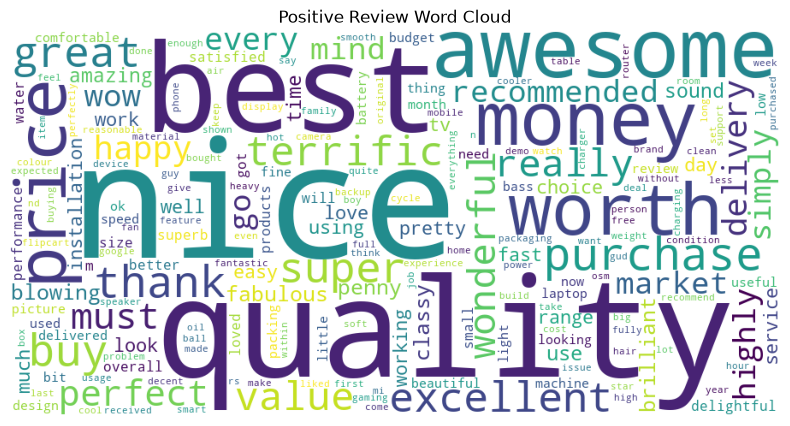

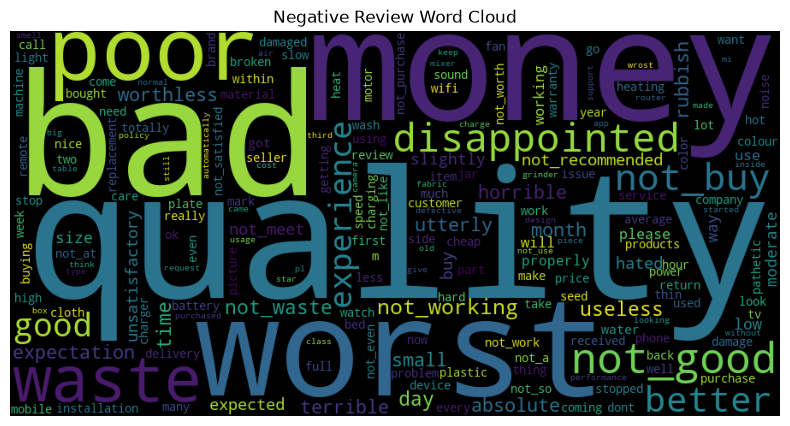

In [12]:
eda.plot_wordcloud(df, "Positive")
eda.plot_wordcloud(df, "Negative")

## 8. LLM analysis (API call)
The LLM provider and model come from `config.yaml` (free Gemini by default; Claude also supported).  
The SVM gives one label per review. The LLM adds **aspect-level** understanding and **product summaries**.
All prompts are in `prompts/prompts.yaml`; model and settings are in `config.yaml`.

In [13]:
prompts = load_prompts(cfg["prompts_path"])
llm = LLMClient(cfg["llm"]) if HAS_KEY else None

review = "Battery easily lasts 12 hours and the sound is crisp, but the cable included in the box is too short."
print("SVM :", classifier.predict(svm, review))
if llm:
    result = analyze_review(llm, prompts, review)
    print("LLM overall:", result["overall"], "|", result["one_line_summary"])
    display(pd.DataFrame(result["aspects"]))
else:
    print("LLM skipped (no API key).")

SVM : Neutral
LLM overall: positive | Excellent battery and sound quality, though the included cable is inconveniently short.


,aspect,sentiment,evidence
0,battery,positive,battery easily lasts 12 hours
1,sound,positive,sound is crisp
2,cable,negative,cable included in the box is too short


In [14]:
# Pros / cons summary for one product, built from a balanced sample of its reviews
if llm:
    s = cfg["summarize"]
    product, n, out = summarize_product(llm, prompts, df, "electric kettle", s["max_reviews"], s["max_chars"])
    print(f"{product}  ({n} reviews analysed)\n")
    print("Verdict:", out["verdict"])
    print("Pros:", *[f"\n  + {p}" for p in out["pros"]])
    print("Cons:", *[f"\n  - {c}" for c in out["cons"]])
    print("\nRecommendation:", out["recommendation"])
else:
    print("LLM skipped (no API key).")

Pigeon Favourite Electric Kettle (1.5 L, Silver, Black)  (45 reviews analysed)

Verdict: Customer satisfaction is highly polarized, with many users reporting severe durability issues and electrical failures, while others find it a convenient and fast tool for basic tasks. The overall consensus is that the product suffers from inconsistent quality control and fragile construction.
Pros: 
  + Boils water very quickly 
  + Affordable price point 
  + Useful for simple tasks like tea or coffee 
  + Compact and convenient for students
Cons: 
  - Frequent electrical failures and short circuits 
  - Very thin and fragile metal body 
  - Short power cord length 
  - Poor quality plastic components 
  - Short product lifespan

Recommendation: Budget-conscious buyers needing a temporary solution may consider it, but those seeking a durable, long-term appliance should avoid this product.


## 9. LLM vs SVM benchmark
Balanced sample (50 per class) from the **held-out test split** (the SVM never saw these). Reviews go to the LLM 10 per call, so this is 15 API calls.
The report gives each accuracy with a **95% confidence interval** and confusion matrices, and is also saved to `reports/compare_report.txt`.
⏱ On a free tier the client waits ~13 s between calls, so this section takes a few minutes.

In [15]:
if llm:
    report, table = run_comparison(llm, prompts, svm, df, cfg)
    print(report)
    table.to_csv(cfg["compare"]["output_path"], index=False)
    display(table[table["svm"] != table["llm"]].head(10))   # where they disagree
else:
    print("LLM skipped (no API key).")

Reviews compared (balanced, held-out): 150
SVM accuracy : 0.960   (95% CI 0.915 - 0.982, n=150)
LLM accuracy : 0.800   (95% CI 0.729 - 0.856, n=150)
SVM/LLM agreement: 0.767

--- LLM per-class report ---
              precision    recall  f1-score   support

    Negative       0.75      0.96      0.84        50
     Neutral       0.83      0.50      0.62        50
    Positive       0.84      0.94      0.89        50

    accuracy                           0.80       150
   macro avg       0.81      0.80      0.78       150
weighted avg       0.81      0.80      0.78       150

--- SVM per-class report ---
              precision    recall  f1-score   support

    Negative       1.00      0.98      0.99        50
     Neutral       0.98      0.90      0.94        50
    Positive       0.91      1.00      0.95        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150

--- L

,Rate,Sentiment,svm,llm,text
5,2.0,Negative,Neutral,Negative,Nan. Short in size
12,2.0,Negative,Negative,Neutral,Expected a better product. The alluminium body part is not properly pasted.....
27,2.0,Negative,Negative,Neutral,"Could be way better. Product was good not damaged , but the screws hole was ..."
52,3.0,Neutral,Neutral,Negative,Just okay. Size is not shown as per in image
54,3.0,Neutral,Neutral,Positive,Fair. Super product
57,3.0,Neutral,Neutral,Positive,Decent product. Price wise is a best product.
60,3.0,Neutral,Neutral,Positive,Does the job. I think durability is the weak side for this flask overall goo...
61,3.0,Neutral,Neutral,Negative,Nan. Not suitable for rough use
62,3.0,Neutral,Neutral,Negative,Does the job. Charging is good but magnetic suction is very loose grip with ...
64,3.0,Neutral,Neutral,Negative,Decent product. Received used product. But in working condition..


**How to read this benchmark (important):**
- The "truth" is the star rating. The SVM was *trained* on exactly that labelling, while the LLM judges the *text*. A gap between them therefore does not prove the LLM is worse.
- Look at the disagreement table: a 3-star review such as "Nice. Not bad" is arguably Positive to a human, yet it counts as an LLM error against the Neutral label. Expect the LLM's weakest class to be **Neutral**.
- With 150 reviews the 95% confidence interval is about ±6-8 points, so only large differences mean anything.
- The LLM's real value here is what the SVM cannot do: aspect-level analysis (section 8) and understanding sarcasm (section 10).

## 10. Try your own review

In [16]:
try:
    text = input("Enter a review: ")
except Exception:
    text = "Great phone but the battery drains quickly"
print("Review:", text)
print("SVM  :", classifier.predict(svm, text))
if llm:
    r = analyze_review(llm, prompts, text)
    print("LLM  :", r["overall"], "|", r["one_line_summary"])
    display(pd.DataFrame(r["aspects"]))

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Review: I bought this wireless mouse expecting it to last at least a few months. The scroll wheel started squeaking on day three, and by day seven, the cursor froze completely. Fresh batteries didn't fix it. Waste of money
SVM  : Negative
LLM  : negative | The mouse failed within a week due to hardware issues and is a waste of money.


,aspect,sentiment,evidence
0,scroll wheel,negative,scroll wheel started squeaking
1,cursor,negative,cursor froze completely
2,battery,negative,Fresh batteries didn't fix it
3,price,negative,Waste of money


## Conclusion
- TF-IDF (with bigrams) + LinearSVC reaches **97.3% accuracy and 0.94 macro-F1** on 20,714 held-out, de-duplicated reviews; Neutral is the hardest class (F1 ≈ 0.87).
- Removing review texts that appeared in both train and test lowered accuracy from 97.8% to 97.3%. The lower number is the honest one.
- Bigrams and balanced class weights fixed the negation failure ("not as expected" was originally predicted Positive).
- The LLM complements the SVM with aspect-level insight, product summaries and an independent check, at higher cost and latency. On star-rating labels it scores below the SVM, which was trained on those labels (see the note in section 9).
- **Limitations:** labels come from star ratings, not human annotation, so they are noisy; the benchmark uses only 150 reviews; the data is one marketplace and mostly English.